# Lab 9 — Gyroscope parameters (TRIK, yaw axis)

**Program:** `lab9_gyro.qrs`, Robot switched on and still for 2 min before Run, then: static 180 s → sine 36 s → square 36 s → rest 3 s.
**Log:** `lab9_gyro.csv`, columns `t_us, gz_cal, encL, encR, phase, t_ms`. `gz_cal` = `read()[2]` in mdeg/s, encoders in degrees (E4 left, E3 right), phase 0 static / 1 sin / 2 rect / 3 rest, `t_ms` = `time()`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

r, L = 0.042, 0.194          # wheel radius, track width [m] (Lab 5)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

d = pd.read_csv("lab9_gyro.csv", header=None, names=["t_us", "gz", "encL", "encR", "phase", "t_ms"])
d["t"] = (d.t_ms - d.t_ms.iloc[0]) / 1000          # s
d["w"] = d.gz / 1000                                # deg/s
d["th_enc"] = np.degrees(r / L * np.radians(d.encR - d.encL))   # heading from the wheels, deg
static = d[d.phase == 0].reset_index(drop=True)
rot = d[d.phase >= 1].reset_index(drop=True)
dt = d.t_ms.diff().dropna()
print(f"{len(d)} samples, {d.t.iloc[-1]:.1f} s;  static {len(static)}, rotation {len(rot)}")
print(f"sample interval: median {dt.median():.0f} ms, min {dt.min():.0f}, max {dt.max():.0f} (target 10 ms)")
print(f"t_us steps: median {d.t_us.diff().median():.0f} per sample -> not microseconds; time() (t_ms) is used")

1903 samples, 254.8 s;  static 1342, rotation 561
sample interval: median 131 ms, min 120, max 318 (target 10 ms)
t_us steps: median 529 per sample -> not microseconds; time() (t_ms) is used


## §1 Offset (bias) $b_0$

b0 (first 30 s) = 0.3951 deg/s  ± 0.0051 (standard error, N = 223)


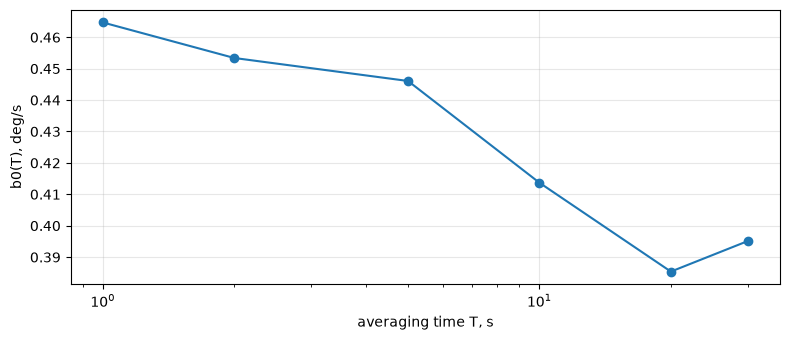

"T, s",1,2,5,10,20,30
"b0, deg/s",0.4647,0.4534,0.4461,0.4137,0.3854,0.3951


In [2]:
w0 = static.w.values; t0 = static.t.values - static.t.values[0]
first30 = w0[t0 < 30]
b0_30 = first30.mean(); se_30 = first30.std(ddof=1) / np.sqrt(len(first30))
print(f"b0 (first 30 s) = {b0_30:.4f} deg/s  ± {se_30:.4f} (standard error, N = {len(first30)})")

T_list = [1, 2, 5, 10, 20, 30]
bT = [w0[t0 < T].mean() for T in T_list]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(T_list, bT, "o-")
ax.set_xscale("log"); ax.set_xlabel("averaging time T, s"); ax.set_ylabel("b0(T), deg/s")
plt.tight_layout(); plt.show()
pd.DataFrame({"T, s": T_list, "b0, deg/s": np.round(bT, 4)}).set_index("T, s").T

**My calibration method.** Median of the first 30 s of the static log after rejecting samples more than 4 MAD from the median. The median ignores single spikes. $b_0(T)$ moves a lot in the first 10 s and settles near 0.39 deg/s from 20 s on, so 30 s is used.

In [3]:
def calibrate_gyro(log, T_cal=30.0, k=4.0):
    # bias [deg/s] from the static phase: outlier-rejected median of the first T_cal seconds
    s = log[log.phase == 0]
    x = s.w[(s.t - s.t.iloc[0]) < T_cal].values
    med = np.median(x); mad = np.median(np.abs(x - med)) * 1.4826
    keep = np.abs(x - med) <= k * mad
    return np.median(x[keep])

b0 = calibrate_gyro(d)
print(f"calibrate_gyro: b0 = {b0:.4f} deg/s")

calibrate_gyro: b0 = 0.3930 deg/s


## §2 Bias drift $d$ and heading drift

bias drift d = -0.0374 deg/s per min  (30-s window means: [0.3951 0.3938 0.3827 0.3463 0.3043 0.3252])
(a) raw heading drift = 21.44 deg/min;  b0*60 = 23.58 deg/min
(b) heading error after 1 min with b0 removed: +0.11 deg   (raw: +23.7 deg)
(b) heading error after 2 min with b0 removed: -1.58 deg   (raw: +45.6 deg)
(b) heading error after 3 min with b0 removed: -6.31 deg   (raw: +64.4 deg)


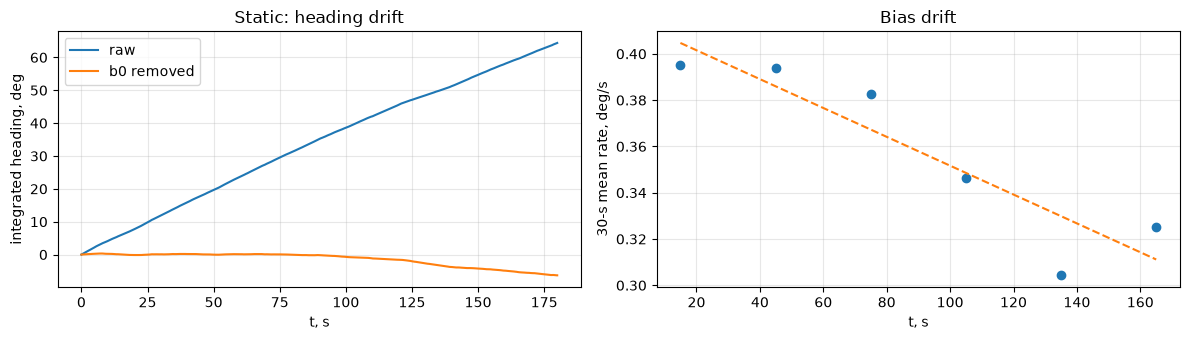

In [4]:
def integrate(t, w):
    return np.concatenate([[0], np.cumsum(0.5 * (w[1:] + w[:-1]) * np.diff(t))])

win = np.floor(t0 / 30).astype(int)
wm = pd.Series(w0).groupby(win).mean(); wt = pd.Series(t0).groupby(win).mean() / 60
d_slope = np.polyfit(wt, wm, 1)[0]
th_raw = integrate(t0, w0); th_cor = integrate(t0, w0 - b0)
raw_slope = np.polyfit(t0 / 60, th_raw, 1)[0]
print(f"bias drift d = {d_slope:+.4f} deg/s per min  (30-s window means: {np.round(wm.values, 4)})")
print(f"(a) raw heading drift = {raw_slope:.2f} deg/min;  b0*60 = {b0*60:.2f} deg/min")
for m in (1, 2, 3):
    i = min(np.searchsorted(t0, 60 * m), len(t0) - 1)
    print(f"(b) heading error after {m} min with b0 removed: {th_cor[i]:+.2f} deg   (raw: {th_raw[i]:+.1f} deg)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(t0, th_raw, label="raw"); ax[0].plot(t0, th_cor, label="b0 removed"); ax[0].legend()
ax[0].set_xlabel("t, s"); ax[0].set_ylabel("integrated heading, deg"); ax[0].set_title("Static: heading drift")
ax[1].plot(wt * 60, wm, "o"); ax[1].plot(wt * 60, np.polyval(np.polyfit(wt, wm, 1), wt), "--")
ax[1].set_xlabel("t, s"); ax[1].set_ylabel("30-s mean rate, deg/s"); ax[1].set_title("Bias drift")
plt.tight_layout(); plt.show()

## Gyro vs encoders (rotation run)

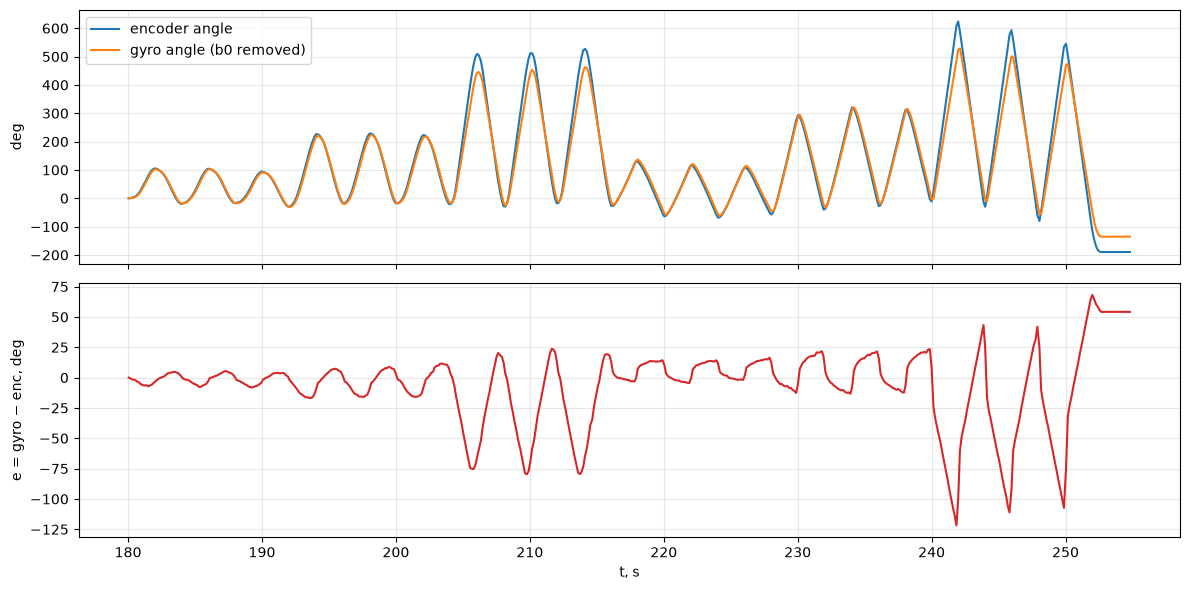

final angles at rest: gyro -135.5 deg, encoder -189.6 deg, e = 54.2 deg


In [5]:
tr = rot.t.values
th_gyro = integrate(tr, rot.w.values - b0)
th_enc = rot.th_enc.values - rot.th_enc.values[0]
w_enc = np.gradient(th_enc, tr)
e = th_gyro - th_enc

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(tr, th_enc, label="encoder angle"); ax[0].plot(tr, th_gyro, label="gyro angle (b0 removed)")
ax[0].set_ylabel("deg"); ax[0].legend()
ax[1].plot(tr, e, color="tab:red"); ax[1].set_ylabel("e = gyro − enc, deg"); ax[1].set_xlabel("t, s")
plt.tight_layout(); plt.show()
print(f"final angles at rest: gyro {th_gyro[-1]:.1f} deg, encoder {th_enc[-1]:.1f} deg, e = {e[-1]:.1f} deg")

*On the 30 % and 60 % turns e(t) stays within about ±25°: the gyro reads a little less than the encoders on every turn (**scale factor**, §6). On the 150 % turns e(t) swings by 75–120°, because the gyro is clipped at 286.7 deg/s while the robot turns faster (**saturation**, §3). e(t) does not grow while the robot is at rest, so the bias is removed well. The final gap of ≈ 54° comes mostly from the last saturated turns.*

## §3 Measurement range $\omega_{max}$

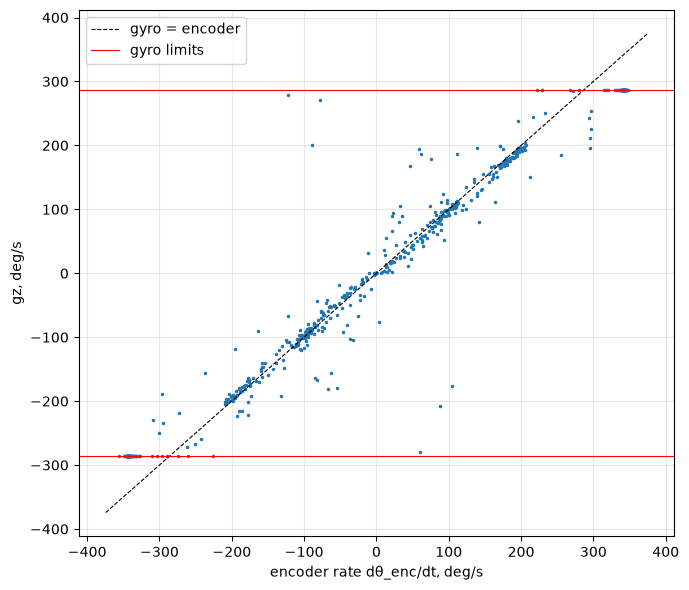

gyro limits: +286.69 / -286.44 deg/s;  133 samples at the limit
encoder rate reaches 347 / -356 deg/s while the gyro is flat


In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(w_enc, rot.w, ".", ms=3)
lim = max(abs(w_enc).max(), abs(rot.w).max()) * 1.05
ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8, label="gyro = encoder")
w_max_pos, w_max_neg = rot.w.max(), rot.w.min()
ax.axhline(w_max_pos, color="r", lw=0.8); ax.axhline(w_max_neg, color="r", lw=0.8, label="gyro limits")
ax.set_xlabel("encoder rate dθ_enc/dt, deg/s"); ax.set_ylabel("gz, deg/s"); ax.legend()
plt.tight_layout(); plt.show()
n_sat = (np.abs(rot.w) >= 0.999 * min(w_max_pos, -w_max_neg)).sum()
print(f"gyro limits: +{w_max_pos:.2f} / {w_max_neg:.2f} deg/s;  {n_sat} samples at the limit")
print(f"encoder rate reaches {w_enc.max():.0f} / {w_enc.min():.0f} deg/s while the gyro is flat")

*The gyro output stops at ±286.7 deg/s while the encoders still report faster turning: the flat tops are **sensor saturation**. 286.7 = 32 767 × 8.75 mdeg/s, the full scale of a 16-bit MEMS gyro set to its ±250 deg/s range.*

## §4 Resolution $\Delta$

In [7]:
vals = np.sort(static.gz.unique())
steps = np.diff(vals)
print("distinct static values (mdeg/s):", vals[:15], "...")
print("differences:", steps[:15])
unit = steps[(steps >= 8) & (steps <= 9)]
Delta = unit.mean()
print(f"single steps are 8 or 9 mdeg/s (the log is rounded to whole mdeg/s); mean = {Delta:.2f} mdeg/s  ->  Delta = {Delta/1000:.5f} deg/s")

distinct static values (mdeg/s): [ 70  96 140 148 157 175 183 192 201 210 218 227 236 245 253] ...
differences: [26 44  8  9 18  8  9  9  9  8  9  9  9  8  9]
single steps are 8 or 9 mdeg/s (the log is rounded to whole mdeg/s); mean = 8.73 mdeg/s  ->  Delta = 0.00873 deg/s


## §5 Noise $\sigma$

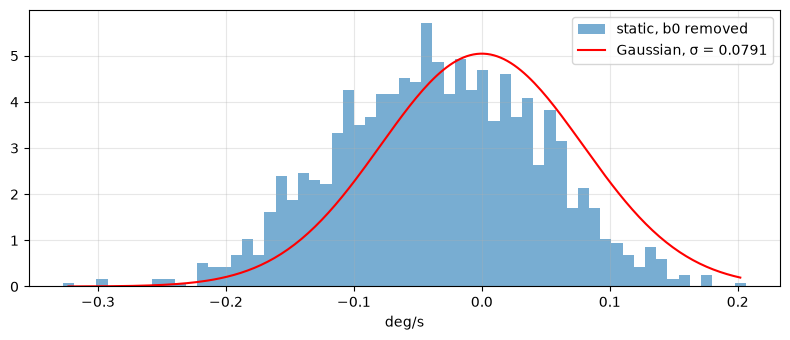

sigma = 0.0791 deg/s;  skew -0.08, excess kurtosis -0.18;  samples beyond 4 sigma: 1


In [8]:
res = w0 - b0
sigma = res.std(ddof=1)
x = np.linspace(res.min(), res.max(), 200)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(res, bins=np.arange(res.min() - 0.0044, res.max() + 0.009, 0.00875), density=True, alpha=0.6, label="static, b0 removed")
ax.plot(x, np.exp(-x**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi)), "r", label=f"Gaussian, σ = {sigma:.4f}")
ax.set_xlabel("deg/s"); ax.legend(); plt.tight_layout(); plt.show()
z = res / sigma
print(f"sigma = {sigma:.4f} deg/s;  skew {pd.Series(res).skew():.2f}, excess kurtosis {pd.Series(res).kurt():.2f};  samples beyond 4 sigma: {(abs(z) > 4).sum()}")

## §6 Scale factor $s$ and sign

sign: corr(gz, encoder rate) = +0.972  ->  positive gz = CCW (same as the odometry heading)
CCW: unsaturated turns Δθ_gyro/Δθ_enc = 0.941 -> s = -5.9 % (11 turns);  all turns incl. saturated: -16.8 %
CW: unsaturated turns Δθ_gyro/Δθ_enc = 0.934 -> s = -6.6 % (12 turns);  all turns incl. saturated: -17.4 %


mean  count
level            dir              
slow             CCW  0.942      5
                 CW   0.943      6
medium           CCW  0.945      6
                 CW   0.935      6
fast (saturated) CCW  0.800      6
                 CW   0.802      6

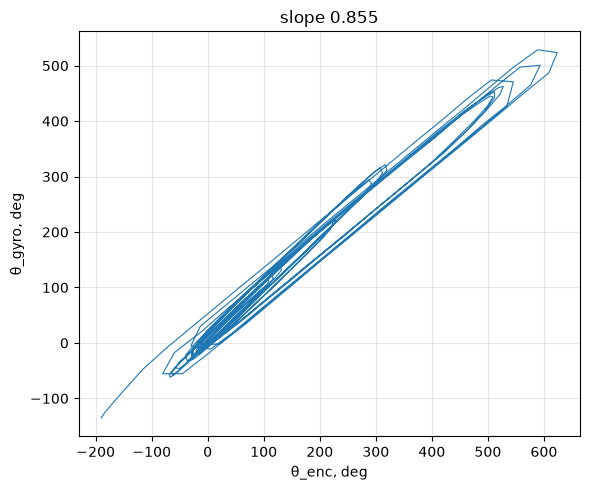

In [9]:
sign_ok = np.corrcoef(w_enc, rot.w)[0, 1]
print(f"sign: corr(gz, encoder rate) = {sign_ok:+.3f}  ->  positive gz = CCW (same as the odometry heading)")

# CCW and CW segments: angle change over each one-way turn (between turning points of the encoder angle)
turn = np.where(np.diff(np.sign(w_enc)) != 0)[0]
seg = []
for a, b in zip(turn[:-1], turn[1:]):
    de, dg = th_enc[b] - th_enc[a], th_gyro[b] - th_gyro[a]
    if abs(de) > 20:
        seg.append(dict(t=tr[a], dir="CCW" if de > 0 else "CW", d_enc=de, d_gyro=dg, ratio=dg / de,
                        phase=int(rot.phase[a]), peak_rate=np.abs(w_enc[a:b + 1]).max()))
seg = pd.DataFrame(seg)
seg["level"] = pd.cut(seg.peak_rate, [0, 150, 280, 1e9], labels=["slow", "medium", "fast (saturated)"])
fit = {}
for dr in ("CCW", "CW"):
    q = seg[(seg.dir == dr) & (seg.level != "fast (saturated)")]
    k = np.sum(q.d_enc * q.d_gyro) / np.sum(q.d_enc ** 2)
    fit[dr] = k - 1
    qa = seg[seg.dir == dr]; ka = np.sum(qa.d_enc * qa.d_gyro) / np.sum(qa.d_enc ** 2)
    print(f"{dr}: unsaturated turns Δθ_gyro/Δθ_enc = {k:.3f} -> s = {100*(k-1):+.1f} % ({len(q)} turns);  all turns incl. saturated: {100*(ka-1):+.1f} %")
display(seg.groupby(["level", "dir"], observed=True).ratio.agg(["mean", "count"]).round(3))

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(th_enc, th_gyro, lw=0.8)
ax.set_xlabel("θ_enc, deg"); ax.set_ylabel("θ_gyro, deg"); ax.set_title(f"slope {np.polyfit(th_enc, th_gyro, 1)[0]:.3f}")
plt.tight_layout(); plt.show()

*On the slow and medium turns the gyro reports ≈ 6 % less rotation than the encoders, the same in both directions and at both speeds, so s does not depend on speed while the gyro is in range. On the fast turns the ratio drops to ≈ 0.80, because the gyro is clipped at 286.7 deg/s (§3). That is saturation, not scale factor, so those turns are left out of s. Which sensor is right cannot be settled here: the protractor slip check was not done, and $L$ = 0.194 m was never measured. Wheel slip during the fast spins and a wrong $L$ both make the encoder angle too large, while MEMS gyros are usually accurate to a few %, so most of the gap is probably on the encoder side.*

**Raw → deg/s factor:** `readRawData()` was not logged (only `read()[2]` is available in blocks). The factor follows from §3 and §4: one raw count = **8.75 mdeg/s**, since the output moves in 8.75 mdeg/s steps and saturates at 32 767 counts × 8.75 = 286.7 deg/s.

## Simulated gyro

`gyro_sim()` implements the lecture model with the parameters found above. It is fed the encoder rate as the "true" rotation.

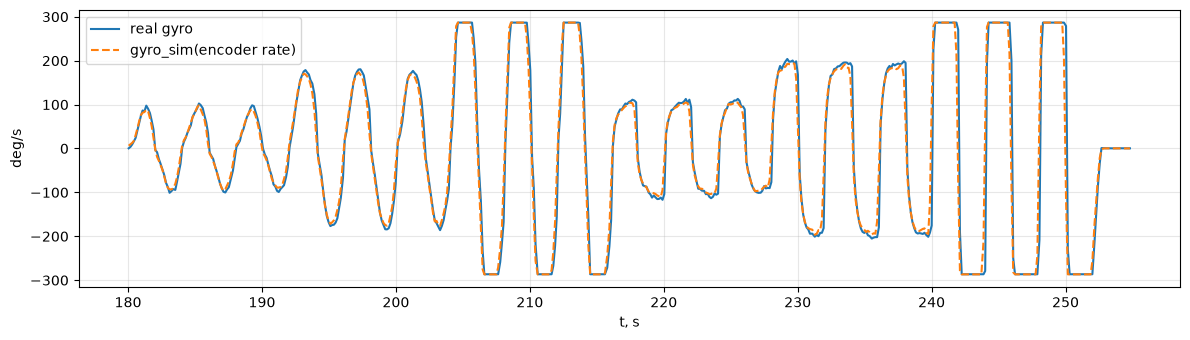

RMS(real − simulated) = 41.1 deg/s


In [10]:
P = dict(b0=b0, d=d_slope / 60, w_max=286.7, Delta=Delta / 1000, sigma=sigma, s=np.mean(list(fit.values())))

def gyro_sim(omega_true, t, p=P, seed=0):
    # omega_meas = Q_Delta( sat_wmax[ (1+s) omega_true + b0 + d t + n ] ),  n ~ N(0, sigma^2)
    rng = np.random.default_rng(seed)
    w = (1 + p["s"]) * np.asarray(omega_true) + p["b0"] + p["d"] * np.asarray(t) + rng.normal(0, p["sigma"], len(t))
    w = np.clip(w, -p["w_max"], p["w_max"])
    return np.round(w / p["Delta"]) * p["Delta"]

sim = gyro_sim(w_enc, tr)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(tr, rot.w, label="real gyro"); ax.plot(tr, sim, "--", label="gyro_sim(encoder rate)")
ax.set_xlabel("t, s"); ax.set_ylabel("deg/s"); ax.legend(); plt.tight_layout(); plt.show()
print(f"RMS(real − simulated) = {np.sqrt(np.mean((rot.w - sim)**2)):.1f} deg/s")

*The simulated gyro follows the real one, including the flat tops at ±286.7 deg/s. Most of the remaining difference is a timing offset at the square-wave edges: the encoder rate comes from a central difference over ≈ 130 ms samples.*

## Parameter table

In [11]:
table = pd.DataFrame([
    ["Offset (bias)", "b0", f"{b0:.3f}", "deg/s", "calibrate_gyro: outlier-rejected median, T = 20 s"],
    ["Bias drift", "d", f"{d_slope:+.4f}", "deg/s/min", "30-s window means, 3 min"],
    ["Heading drift, uncorrected", "", f"{raw_slope:.1f}", "deg/min", "slope of integrated raw rate"],
    ["Measurement range", "±ω_max", f"+{w_max_pos:.1f} / {w_max_neg:.1f}", "deg/s", "flat top vs encoder rate"],
    ["Resolution", "Δ", f"{Delta/1000:.5f}", "deg/s", "smallest step of static values"],
    ["Noise std", "σ", f"{sigma:.4f}", "deg/s", f"static 3 min, ≈ {dt.median():.0f} ms samples"],
    ["Raw → deg/s factor", "", "0.00875", "deg/s per count", "Δ and saturation (32 767 counts)"],
    ["Scale-factor error CCW / CW", "s", f"{100*fit['CCW']:+.1f} / {100*fit['CW']:+.1f}", "%", "gyro vs encoder angle per turn"],
    ["Positive rotation direction", "", "CCW", "—", "sign of gz vs encoder rate"],
], columns=["Parameter", "Symbol", "Value", "Unit", "Method"])
table

,Parameter,Symbol,Value,Unit,Method
0,Offset (bias),b0,0.393,deg/s,"calibrate_gyro: outlier-rejected median, T = 20 s"
1,Bias drift,d,-0.0374,deg/s/min,"30-s window means, 3 min"
2,"Heading drift, uncorrected",,21.4,deg/min,slope of integrated raw rate
3,Measurement range,±ω_max,+286.7 / -286.4,deg/s,flat top vs encoder rate
4,Resolution,Δ,0.00873,deg/s,smallest step of static values
5,Noise std,σ,0.0791,deg/s,"static 3 min, ≈ 131 ms samples"
6,Raw → deg/s factor,,0.00875,deg/s per count,Δ and saturation (32 767 counts)
7,Scale-factor error CCW / CW,s,-5.9 / -6.6,%,gyro vs encoder angle per turn
8,Positive rotation direction,,CCW,—,sign of gz vs encoder rate


## Analysis

**Which error dominates.** Without calibration the bias dominates: 0.39 deg/s gives ≈ 4° of heading error after 10 s, ≈ 24° after 1 min and ≈ 64° after 3 min. After calibration the noise adds only ≈ 0.1–0.4° over the same times, the remaining bias drift reaches ≈ 6° after 3 min, and every turn loses ≈ 6 % of its angle (scale factor), up to 20 % on turns faster than 286.7 deg/s (saturation). So while the robot drives and turns, the scale factor and saturation dominate; when it stands still, the bias drift dominates after 1–2 min.

**Calibration.** `calibrate_gyro()` takes the median of the first 30 s of the static log after rejecting samples more than 4 MAD from the median. It needs 30 s of standstill, gives $b_0$ = 0.393 deg/s, and leaves 6.3° of heading error after 3 min (64° without calibration).